In [2]:
import importlib
import nystrom_functions
importlib.reload(nystrom_functions)

import numpy as np
import matplotlib.pyplot as plt
import time
import pandas as pd

from sklearn.preprocessing import StandardScaler
from KRR_utils import *
from nystrom_functions import *

In [3]:
# data setup and full KRR baseline

df = pd.read_csv("../Data/train.csv")
X = df.iloc[:, :-1].to_numpy(dtype=float)
y = df.iloc[:, -1].to_numpy(dtype=float)

cycles = 5  
split_seed = 1  # the train/test data split remain fixed across all repetitions
method_seed = 1000  # starting seed for Nystrom methods
split_rng = np.random.default_rng(split_seed)  

# sample sizes for training and testing
n_train = 19000 #add 0
n_test = 1000

# this is the KRR lambda in (K + lambda I) * alpha = y
krr_lam = 1e-2

# sampled columns for uniform and approximate leverage
l_values = [50, 100, 200, 400, 800, 1600]

# this is the recursive parameter, not the same lamda for some reason
rec_lam_values = [1000, 2000, 5000, 10000, 20000] #add 0
rec_delta = 0.1
rec_base_size = None # for testing

# approximate leverage starts with these many uniform columns
ini_l_fixed = 100 #100

# this is a check that compares the factorized solver to an explicit solve of (K_tilde + lambda I) only used to verify the solver works
check_explicit_solve = False

ind = split_rng.choice(X.shape[0], size=n_train + n_test, replace=False)  

train_ind = ind[:n_train]
test_ind = ind[n_train:]
X_train_raw = X[train_ind]
y_train = y[train_ind]
X_test_raw = X[test_ind]
y_test = y[test_ind]

# free the complete dataset after making the fixed split 
del df, X, y

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_test = scaler.transform(X_test_raw)

gamma = 1 / X_train.shape[1]

def rbf_final(A, B):
    K = rbf(A, B, gamma=gamma)
    return K

def get_mse(y_true, y_pred):
    err = np.mean((y_true - y_pred)**2)
    return err

dataset = "Superconductivity"  # only the Superconductivity cycled results

print("cycles =", cycles)
print("n_train =", n_train)
print("n_test =", n_test)
print("krr lambda =", krr_lam)
print("gamma =", gamma)

# full kernel direct form
start_time = time.perf_counter()
K_train = rbf_final(X_train, X_train)
K_test = rbf_final(X_test, X_train)
full_kernel_time = time.perf_counter() - start_time
full_solve_times = []

for cycle in range(cycles):
    print("full KRR cycle", cycle + 1, "of", cycles)

    start_time = time.perf_counter()

    alpha_full = np.linalg.solve(
        K_train + krr_lam*np.eye(n_train),
        y_train
    )
    y_hat_full = K_test @ alpha_full

    full_solve_times.append(time.perf_counter() - start_time)

full_solve_time = np.mean(full_solve_times)
full_solve_variance = np.var(full_solve_times, ddof=1)
full_solve_std = np.std(full_solve_times, ddof=1)
full_total_time = full_kernel_time + full_solve_time
full_mse = get_mse(y_test, y_hat_full)

K_norm = np.linalg.norm(K_train, ord="fro")
y_norm = np.linalg.norm(y_train)
alpha_norm = np.linalg.norm(alpha_full)

print("full KRR mse =", full_mse)
print("full kernel time =", full_kernel_time)
print("mean full solve time =", full_solve_time)
print("full solve time variance =", full_solve_variance)
print("full solve time std =", full_solve_std)
print("full total time with mean solve time =", full_total_time)

cycles = 5
n_train = 19000
n_test = 1000
krr lambda = 0.01
gamma = 0.012345679012345678
full KRR cycle 1 of 5
full KRR cycle 2 of 5
full KRR cycle 3 of 5
full KRR cycle 4 of 5
full KRR cycle 5 of 5
full KRR mse = 116.53541200161642
full kernel time = 6.370457200000033
mean full solve time = 17.970584659999997
full solve time variance = 0.17951734572498684
full solve time std = 0.4236948733758609
full total time with mean solve time = 24.34104186000003


In [4]:
# uniform and approximate leverage experiments

rows = []

for cycle in range(1, cycles + 1):
    print("cycle", cycle, "of", cycles, " uniform and approximate leverage")
    uniform_rng = np.random.default_rng(method_seed + cycle)
    approx_rng = np.random.default_rng(method_seed + cycle + 1000)

    for l in l_values:
        print("")
        print("l =", l)

        # uniform sampling
        
        print("uniform")

        start_time = time.perf_counter()
        uni_ind = uniform_sampling(n_train, l, uniform_rng)  
        sample_time = time.perf_counter() - start_time

        start_time = time.perf_counter()
        alpha_uni, y_hat_uni, U_uni, eig_uni, C_uni, W_uni = solver(
            X_train,
            rbf_final,
            uni_ind,
            y_train,
            krr_lam,
            X_test=X_test,
            return_factors=True
        )
        solve_time = time.perf_counter() - start_time

        K_uni = (U_uni * eig_uni) @ U_uni.T

        uni_kernel_err = np.linalg.norm(K_train - K_uni, ord="fro") / K_norm
        uni_alpha_err = np.linalg.norm(alpha_full - alpha_uni) / alpha_norm
        uni_mse = get_mse(y_test, y_hat_uni)

        if check_explicit_solve:
            alpha_uni_explicit = np.linalg.solve(K_uni + krr_lam*np.eye(n_train), y_train)
            uni_solver_err = np.linalg.norm(alpha_uni - alpha_uni_explicit) / np.linalg.norm(alpha_uni_explicit)
        else:
            uni_solver_err = np.nan

        rows.append([
            cycle,
            l,
            "uniform",
            np.nan, #empty column for rls
            uni_kernel_err,
            uni_alpha_err,
            uni_solver_err,
            uni_mse,
            sample_time,
            solve_time,
            sample_time + solve_time
        ])

        print("kernel error =", uni_kernel_err)
        print("alpha error =", uni_alpha_err)
        print("test mse =", uni_mse)
        print("sample_time =", sample_time)
        print("solve_time =", solve_time)
        print("time =", sample_time + solve_time)


        # approximate leverage sampling
        
        print("approx leverage")

        ini_l = min(ini_l_fixed, max(1, l // 2))
        extra_l = l - ini_l

        start_time = time.perf_counter()
        app_ind, app_scores, ini_ind = approximate_leverage_kernel(
            X_train,
            rbf_final,
            ini_l,
            extra_l,
            approx_rng
        )
        sample_time = time.perf_counter() - start_time

        start_time = time.perf_counter()
        alpha_app, y_hat_app, U_app, eig_app, C_app, W_app = solver(
            X_train,
            rbf_final,
            app_ind,
            y_train,
            krr_lam,
            X_test=X_test,
            return_factors=True
        )
        solve_time = time.perf_counter() - start_time

        K_app = (U_app * eig_app) @ U_app.T

        app_kernel_err = np.linalg.norm(K_train - K_app, ord="fro") / K_norm
        app_alpha_err = np.linalg.norm(alpha_full - alpha_app) / alpha_norm
        app_mse = get_mse(y_test, y_hat_app)

        if check_explicit_solve:
            alpha_app_explicit = np.linalg.solve(K_app + krr_lam*np.eye(n_train), y_train)
            app_solver_err = np.linalg.norm(alpha_app - alpha_app_explicit) / np.linalg.norm(alpha_app_explicit)
        else:
            app_solver_err = np.nan

        rows.append([
            cycle,
            len(app_ind),
            "approx leverage",
            np.nan,
            app_kernel_err,
            app_alpha_err,
            app_solver_err,
            app_mse,
            sample_time,
            solve_time,
            sample_time + solve_time
        ])

        print("kernel error =", app_kernel_err)
        print("alpha error =", app_alpha_err)
        print("test mse =", app_mse)
        print("sample_time =", sample_time)
        print("solve_time =", solve_time)
        print("time =", sample_time + solve_time)

cycle 1 of 5  uniform and approximate leverage

l = 50
uniform
kernel error = 0.10224201842777542
alpha error = 1.0960114608009324
test mse = 263.05385600569355
sample_time = 0.010366599999997561
solve_time = 0.15371589999995194
time = 0.1640824999999495
approx leverage
kernel error = 0.08565752715007553
alpha error = 1.1498714842362152
test mse = 268.0225381270078
sample_time = 0.10642089999998916
solve_time = 0.06132289999993645
time = 0.1677437999999256

l = 100
uniform
kernel error = 0.0466064575627437
alpha error = 0.9885372114081569
test mse = 227.1417572893265
sample_time = 6.359999997584964e-05
solve_time = 0.22137029999998958
time = 0.22143389999996543
approx leverage
kernel error = 0.05830250386066337
alpha error = 0.9879693617946332
test mse = 225.59259564646905
sample_time = 0.17635140000004412
solve_time = 0.1655623999999989
time = 0.341913800000043

l = 200
uniform
kernel error = 0.03275791577908115
alpha error = 0.8022235954372328
test mse = 200.11249361982232
sample_tim

In [5]:
# recursive RLS
k_diag_train = np.diag(K_train).copy()

for cycle in range(1, cycles + 1):
    print("main experiment cycle", cycle, "of", cycles, "- recursive RLS")
    recursive_rng = np.random.default_rng(method_seed + cycle + 2000)

    for rec_lam in rec_lam_values:
        print("")
        print("recursive RLS, rec_lam =", rec_lam)

        start_time = time.perf_counter()
        rec_ind, rec_weight = recursive_nystrom(
            X_train,
            rbf_final,
            rec_lam,
            rec_delta,
            recursive_rng,
            k_diag_train,
            rec_base_size
        )
        sample_time = time.perf_counter() - start_time

        start_time = time.perf_counter()
        alpha_rec, y_hat_rec, U_rec, eig_rec, C_rec, W_rec = solver(
            X_train,
            rbf_final,
            rec_ind,
            y_train,
            krr_lam,
            X_test=X_test,
            return_factors=True
        )
        solve_time = time.perf_counter() - start_time

        K_rec = (U_rec * eig_rec) @ U_rec.T

        rec_kernel_err = np.linalg.norm(K_train - K_rec, ord="fro") / K_norm
        rec_alpha_err = np.linalg.norm(alpha_full - alpha_rec) / alpha_norm
        rec_mse = get_mse(y_test, y_hat_rec)

        if check_explicit_solve:
            alpha_rec_explicit = np.linalg.solve(K_rec + krr_lam*np.eye(n_train), y_train)
            rec_solver_err = np.linalg.norm(alpha_rec - alpha_rec_explicit) / np.linalg.norm(alpha_rec_explicit)
        else:
            rec_solver_err = np.nan

        rows.append([
            cycle,
            len(rec_ind),
            "recursive RLS",
            rec_lam,
            rec_kernel_err,
            rec_alpha_err,
            rec_solver_err,
            rec_mse,
            sample_time,
            solve_time,
            sample_time + solve_time
        ])

        print("selected columns =", len(rec_ind))
        print("kernel error =", rec_kernel_err)
        print("alpha error =", rec_alpha_err)
        print("test mse =", rec_mse)
        print("sample_time =", sample_time)
        print("solve_time =", solve_time)
        print("time =", sample_time + solve_time)

main experiment cycle 1 of 5 - recursive RLS

recursive RLS, rec_lam = 1000
selected columns = 1495
kernel error = 0.003996434320849105
alpha error = 0.3414352732842578
test mse = 126.93517735675576
sample_time = 2.4676551000000018
solve_time = 6.19046000000003
time = 8.658115100000032

recursive RLS, rec_lam = 2000
selected columns = 747
kernel error = 0.008357439091785991
alpha error = 0.5251339940671395
test mse = 154.027274121885
sample_time = 1.1241878999999244
solve_time = 5.522676700000034
time = 6.646864599999958

recursive RLS, rec_lam = 5000
selected columns = 305
kernel error = 0.023745592162495693
alpha error = 0.7084479534788325
test mse = 175.4072674743046
sample_time = 0.7978694000000814
solve_time = 3.5942115000000285
time = 4.39208090000011

recursive RLS, rec_lam = 10000
selected columns = 144
kernel error = 0.039350166082938454
alpha error = 0.8917890009287409
test mse = 262.5122891609156
sample_time = 0.970715499999983
solve_time = 0.24983899999995174
time = 1.22055

In [6]:
# table

columns = [
    "cycle",
    "l",
    "method",
    "rec_lam",
    "relative_kernel_error",
    "relative_alpha_error",
    "explicit_solver_error",
    "test_mse",
    "sample_time",
    "solve_time",
    "total_time"
]

results = pd.DataFrame(rows, columns=columns)
results["test_rmse"] = np.sqrt(results["test_mse"])  # RMSE is calculated separately for every trial
results["relative_excess_rmse"] = (results["test_rmse"] - np.sqrt(full_mse)) / np.sqrt(full_mse)
results["parameter"] = results["l"]
results.loc[results["method"] == "recursive RLS", "parameter"] = results.loc[results["method"] == "recursive RLS", "rec_lam"]

summary_results = results.groupby(["method", "parameter"], as_index=False).agg(
    l_mean=("l", "mean"),  # recursive RLS is placed at its average selected column count
    l_variance=("l", "var"),
    l_std=("l", "std"),
    relative_kernel_error_mean=("relative_kernel_error", "mean"),  # empirical expectation
    relative_kernel_error_variance=("relative_kernel_error", "var"),  # sample variance
    relative_kernel_error_std=("relative_kernel_error", "std"),
    relative_alpha_error_mean=("relative_alpha_error", "mean"),
    relative_alpha_error_variance=("relative_alpha_error", "var"),
    relative_alpha_error_std=("relative_alpha_error", "std"),
    test_mse_mean=("test_mse", "mean"),
    test_mse_variance=("test_mse", "var"),
    test_mse_std=("test_mse", "std"),
    test_rmse_mean=("test_rmse", "mean"),
    test_rmse_variance=("test_rmse", "var"),
    test_rmse_std=("test_rmse", "std"),
    relative_excess_rmse_mean=("relative_excess_rmse", "mean"),
    relative_excess_rmse_variance=("relative_excess_rmse", "var"),
    relative_excess_rmse_std=("relative_excess_rmse", "std"),
    sample_time_mean=("sample_time", "mean"),
    sample_time_variance=("sample_time", "var"),
    sample_time_std=("sample_time", "std"),
    solve_time_mean=("solve_time", "mean"),
    solve_time_variance=("solve_time", "var"),
    solve_time_std=("solve_time", "std"),
    total_time_mean=("total_time", "mean"),
    total_time_variance=("total_time", "var"),
    total_time_std=("total_time", "std")
)

results.to_csv("../Results/" + dataset + "final_cycleed_raw_results.csv", index=False)
summary_results.to_csv("../Results/" + dataset + "final_cycleed_summary_results.csv", index=False)

print("individual cycleed runs")
display(results)
print("expectation, variance, and standard deviation")
summary_results

individual cycleed runs


,cycle,l,method,rec_lam,relative_kernel_error,relative_alpha_error,explicit_solver_error,test_mse,sample_time,solve_time,total_time,test_rmse,relative_excess_rmse,parameter
0,1,50,uniform,NaN,0.102242,1.096011,NaN,263.053856,0.010367,0.153716,0.164082,16.218935,0.502427,50
1,1,50,approx leverage,NaN,0.085658,1.149871,NaN,268.022538,0.106421,0.061323,0.167744,16.371394,0.516550,50
2,1,100,uniform,NaN,0.046606,0.988537,NaN,227.141757,0.000064,0.221370,0.221434,15.071223,0.396110,100
3,1,100,approx leverage,NaN,0.058303,0.987969,NaN,225.592596,0.176351,0.165562,0.341914,15.019740,0.391341,100
4,1,200,uniform,NaN,0.032758,0.802224,NaN,200.112494,0.000079,0.411208,0.411287,14.146112,0.310413,200
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
80,5,1419,recursive RLS,1000.0,0.004111,0.380921,NaN,131.198705,2.074017,6.000158,8.074175,11.454200,0.061050,1000
81,5,698,recursive RLS,2000.0,0.009438,0.545053,NaN,155.214775,1.456444,2.123274,3.579718,12.458522,0.154084,2000
82,5,286,recursive RLS,5000.0,0.022628,0.701067,NaN,176.874700,0.883402,0.854811,1.738213,13.299425,0.231981,5000
83,5,147,recursive RLS,10000.0,0.039098,0.875400,NaN,207.942581,0.669923,0.325475,0.995398,14.420214,0.335804,10000


expectation, variance, and standard deviation


,method,parameter,l_mean,l_variance,l_std,relative_kernel_error_mean,relative_kernel_error_variance,relative_kernel_error_std,relative_alpha_error_mean,relative_alpha_error_variance,...,relative_excess_rmse_std,sample_time_mean,sample_time_variance,sample_time_std,solve_time_mean,solve_time_variance,solve_time_std,total_time_mean,total_time_variance,total_time_std
0,approx leverage,50,50.0,0.0,0.000000,0.091379,4.741345e-05,0.006886,1.127353,0.000908,...,0.036090,0.099748,3.884701e-05,0.006233,0.086123,0.000307,0.017531,0.185871,0.000340,0.018429
1,approx leverage,100,100.0,0.0,0.000000,0.056074,3.125920e-05,0.005591,1.012771,0.000314,...,0.014547,0.142001,4.015569e-04,0.020039,0.163914,0.000002,0.001553,0.305915,0.000445,0.021093
2,approx leverage,200,200.0,0.0,0.000000,0.031274,5.179512e-06,0.002276,0.800709,0.001066,...,0.022665,0.194878,1.311353e-04,0.011451,0.424697,0.049033,0.221433,0.619575,0.052064,0.228174
3,approx leverage,400,400.0,0.0,0.000000,0.020530,9.685202e-06,0.003112,0.645969,0.000056,...,0.011190,0.199631,1.084080e-04,0.010412,2.662213,2.948429,1.717099,2.861844,2.982920,1.727113
4,approx leverage,800,800.0,0.0,0.000000,0.013001,2.961758e-06,0.001721,0.473179,0.000262,...,0.007967,0.205805,7.452652e-04,0.027300,4.447215,1.243334,1.115049,4.653021,1.197152,1.094145
5,approx leverage,1600,1600.0,0.0,0.000000,0.007608,8.138934e-08,0.000285,0.315054,0.000055,...,0.010471,0.204152,1.554720e-04,0.012469,9.215109,7.352380,2.711527,9.419261,7.304068,2.702604
6,recursive RLS,1000,1506.0,4667.5,68.319104,0.003883,8.096987e-08,0.000285,0.347202,0.000370,...,0.010359,2.362237,6.558388e-02,0.256094,7.010340,0.738673,0.859461,9.372578,0.990482,0.995230
7,recursive RLS,2000,750.2,956.7,30.930567,0.008660,3.506564e-07,0.000592,0.524571,0.000352,...,0.015973,1.414273,3.959525e-02,0.198986,4.148126,2.064977,1.437003,5.562400,2.055168,1.433586
8,recursive RLS,5000,295.6,517.8,22.755219,0.022904,2.508166e-06,0.001584,0.702075,0.000459,...,0.012989,0.864788,3.258896e-03,0.057087,1.981526,1.113140,1.055055,2.846313,1.078534,1.038525
9,recursive RLS,10000,137.2,105.7,10.281051,0.038590,1.032883e-05,0.003214,0.904723,0.000635,...,0.067228,0.722433,2.174654e-02,0.147467,0.255675,0.001573,0.039658,0.978108,0.022972,0.151565


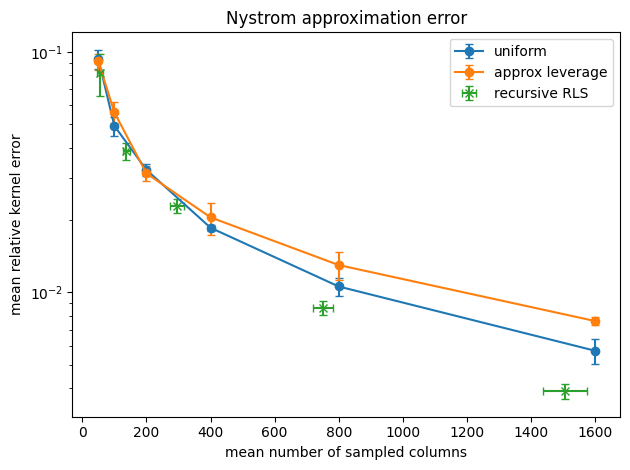

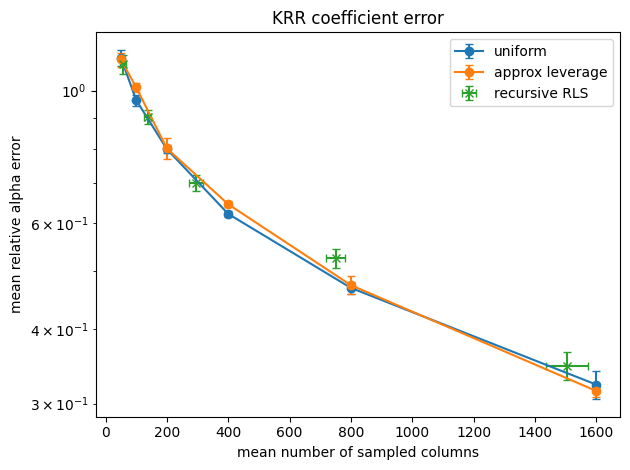

In [ ]:
# main plots

plot_df = summary_results.copy()

plt.figure()
for method in ["uniform", "approx leverage"]:
    sub = plot_df[plot_df["method"] == method].sort_values("l_mean")
    plt.errorbar(sub["l_mean"], sub["relative_kernel_error_mean"], yerr=sub["relative_kernel_error_std"], marker="o", capsize=3, label=method)
sub = plot_df[plot_df["method"] == "recursive RLS"]
plt.errorbar(sub["l_mean"], sub["relative_kernel_error_mean"], xerr=sub["l_std"], yerr=sub["relative_kernel_error_std"], fmt="x", capsize=3, linestyle="none", label="recursive RLS")
plt.yscale("log")
plt.xlabel("mean number of sampled columns")
plt.ylabel("mean relative kernel error")
plt.title("Nystrom approximation error")
plt.legend()
plt.tight_layout()
#plt.savefig("../Results/" + dataset + "final_kernel_error_vs_l.pdf")
plt.show()

plt.figure()
for method in ["uniform", "approx leverage"]:
    sub = plot_df[plot_df["method"] == method].sort_values("l_mean")
    plt.errorbar(sub["l_mean"], sub["relative_alpha_error_mean"], yerr=sub["relative_alpha_error_std"], marker="o", capsize=3, label=method)
sub = plot_df[plot_df["method"] == "recursive RLS"]
plt.errorbar(sub["l_mean"], sub["relative_alpha_error_mean"], xerr=sub["l_std"], yerr=sub["relative_alpha_error_std"], fmt="x", capsize=3, linestyle="none", label="recursive RLS")
plt.yscale("log")
plt.xlabel("mean number of sampled columns")
plt.ylabel("mean relative alpha error")
plt.title("KRR coefficient error")
plt.legend()
plt.tight_layout()
#plt.savefig("../Results/" + dataset + "final_alpha_error_vs_l.pdf")
plt.show()

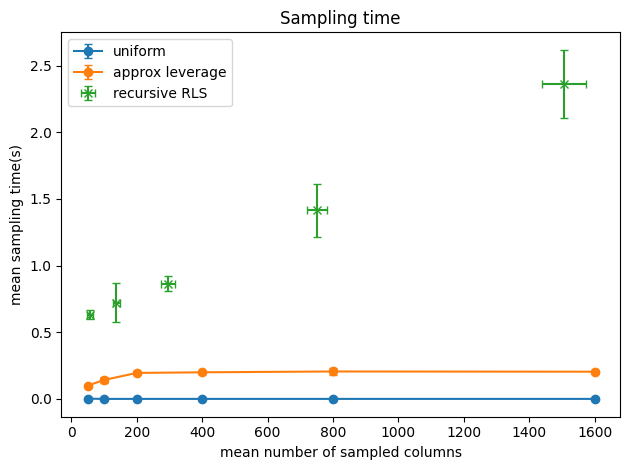

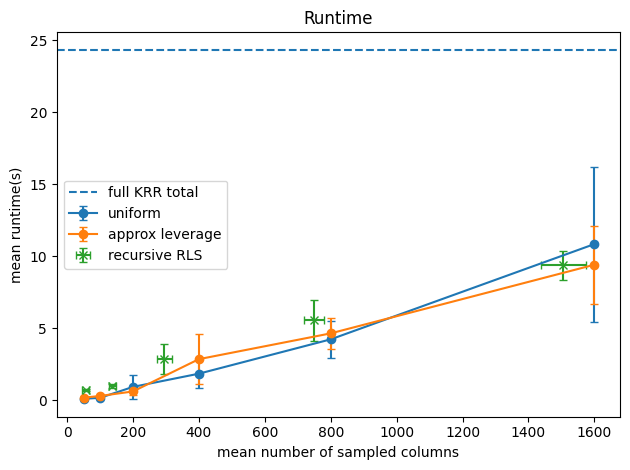

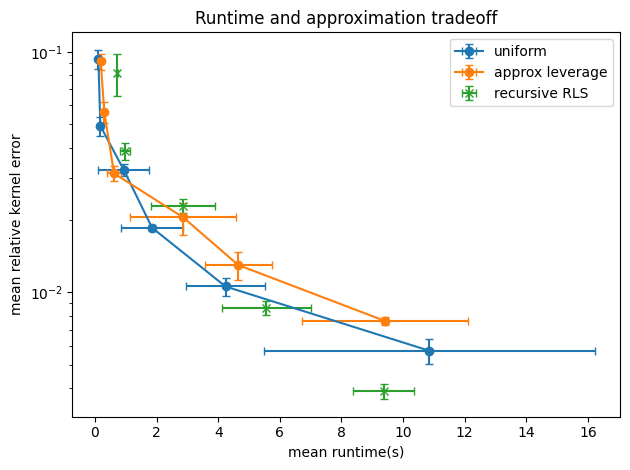

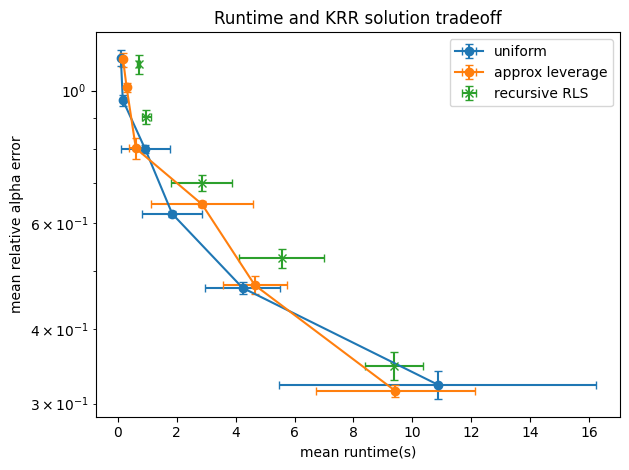

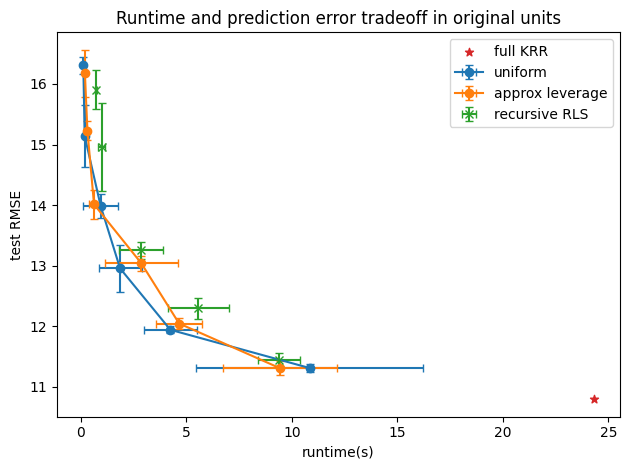

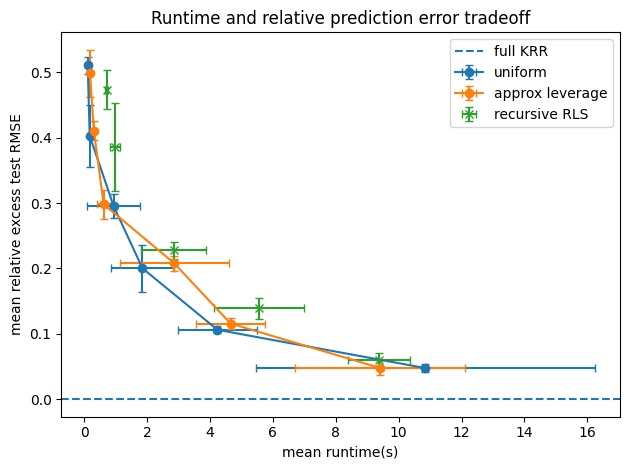

In [ ]:
# runtime plots

plt.figure()
for method in ["uniform", "approx leverage"]:
    sub = plot_df[plot_df["method"] == method].sort_values("l_mean")
    plt.errorbar(sub["l_mean"], sub["sample_time_mean"], yerr=sub["sample_time_std"], marker="o", capsize=3, label=method)
sub = plot_df[plot_df["method"] == "recursive RLS"]
plt.errorbar(sub["l_mean"], sub["sample_time_mean"], xerr=sub["l_std"], yerr=sub["sample_time_std"], fmt="x", capsize=3, linestyle="none", label="recursive RLS")
plt.xlabel("mean number of sampled columns")
plt.ylabel("mean sampling time(s)")
plt.title("Sampling time")
plt.legend()
plt.tight_layout()
#plt.savefig("../Results/" + dataset + "final_sample_time_vs_l.pdf")
plt.show()

plt.figure()
for method in ["uniform", "approx leverage"]:
    sub = plot_df[plot_df["method"] == method].sort_values("l_mean")
    plt.errorbar(sub["l_mean"], sub["total_time_mean"], yerr=sub["total_time_std"], marker="o", capsize=3, label=method)
sub = plot_df[plot_df["method"] == "recursive RLS"]
plt.errorbar(sub["l_mean"], sub["total_time_mean"], xerr=sub["l_std"], yerr=sub["total_time_std"], fmt="x", capsize=3, linestyle="none", label="recursive RLS")
plt.axhline(full_total_time, linestyle="--", label="full KRR total")
plt.xlabel("mean number of sampled columns")
plt.ylabel("mean runtime(s)")
plt.title("Runtime")
plt.legend()
plt.tight_layout()
#plt.savefig("../Results/" + dataset + "final_total_time_vs_l.pdf")
plt.show()

plt.figure()
for method in ["uniform", "approx leverage"]:
    sub = plot_df[plot_df["method"] == method].sort_values("total_time_mean")
    plt.errorbar(sub["total_time_mean"], sub["relative_kernel_error_mean"], xerr=sub["total_time_std"], yerr=sub["relative_kernel_error_std"], marker="o", capsize=3, label=method)
sub = plot_df[plot_df["method"] == "recursive RLS"]
plt.errorbar(sub["total_time_mean"], sub["relative_kernel_error_mean"], xerr=sub["total_time_std"], yerr=sub["relative_kernel_error_std"], fmt="x", capsize=3, linestyle="none", label="recursive RLS")
plt.yscale("log")
plt.xlabel("mean runtime(s)")
plt.ylabel("mean relative kernel error")
plt.title("Runtime and approximation tradeoff")
plt.legend()
plt.tight_layout()
#plt.savefig("../Results/" + dataset + "final_runtime_kernel_error_tradeoff.pdf")
plt.show()

plt.figure()
for method in ["uniform", "approx leverage"]:
    sub = plot_df[plot_df["method"] == method].sort_values("total_time_mean")
    plt.errorbar(sub["total_time_mean"], sub["relative_alpha_error_mean"], xerr=sub["total_time_std"], yerr=sub["relative_alpha_error_std"], marker="o", capsize=3, label=method)
sub = plot_df[plot_df["method"] == "recursive RLS"]
plt.errorbar(sub["total_time_mean"], sub["relative_alpha_error_mean"], xerr=sub["total_time_std"], yerr=sub["relative_alpha_error_std"], fmt="x", capsize=3, linestyle="none", label="recursive RLS")
plt.yscale("log")
plt.xlabel("mean runtime(s)")
plt.ylabel("mean relative alpha error")
plt.title("Runtime and KRR solution tradeoff")
plt.legend()
plt.tight_layout()
#plt.savefig("../Results/" + dataset + "final_runtime_alpha_error_tradeoff.pdf")
plt.show()
plt.figure()

for method in ["uniform", "approx leverage"]:
    sub = plot_df[plot_df["method"] == method].sort_values("total_time_mean")

    plt.errorbar(
        sub["total_time_mean"],
        sub["test_rmse_mean"],
        xerr=sub["total_time_std"],
        yerr=sub["test_rmse_std"],
        marker="o",
        capsize=3,
        label=method
    )

sub = plot_df[plot_df["method"] == "recursive RLS"]

plt.errorbar(
    sub["total_time_mean"],
    sub["test_rmse_mean"],
    xerr=sub["total_time_std"],
    yerr=sub["test_rmse_std"],
    fmt="x",
    capsize=3,
    linestyle="none",
    label="recursive RLS"
)

plt.scatter(
    [full_total_time],
    [np.sqrt(full_mse)],
    marker="*",
    color="tab:red",
    label="full KRR"
)

plt.xlabel("runtime(s)")
plt.ylabel("test RMSE")
plt.title("Runtime and prediction error tradeoff in original units")
plt.legend()
plt.tight_layout()
#plt.savefig("../Results/" + dataset + "final_runtime_test_rmse_tradeoff.pdf")
plt.show()
plt.figure()
for method in ["uniform", "approx leverage"]:
    sub = plot_df[plot_df["method"] == method].sort_values("total_time_mean")
    plt.errorbar(sub["total_time_mean"], sub["relative_excess_rmse_mean"], xerr=sub["total_time_std"], yerr=sub["relative_excess_rmse_std"], marker="o", capsize=3, label=method)
sub = plot_df[plot_df["method"] == "recursive RLS"]
plt.errorbar(sub["total_time_mean"], sub["relative_excess_rmse_mean"], xerr=sub["total_time_std"], yerr=sub["relative_excess_rmse_std"], fmt="x", capsize=3, linestyle="none", label="recursive RLS")
plt.axhline(0, linestyle="--", label="full KRR")
plt.xlabel("mean runtime(s)")
plt.ylabel("mean relative excess test RMSE")
plt.title("Runtime and relative prediction error tradeoff")
plt.legend()
plt.tight_layout()
#plt.savefig("../Results/" + dataset + "final_runtime_relative_excess_rmse_tradeoff.pdf")
plt.show()

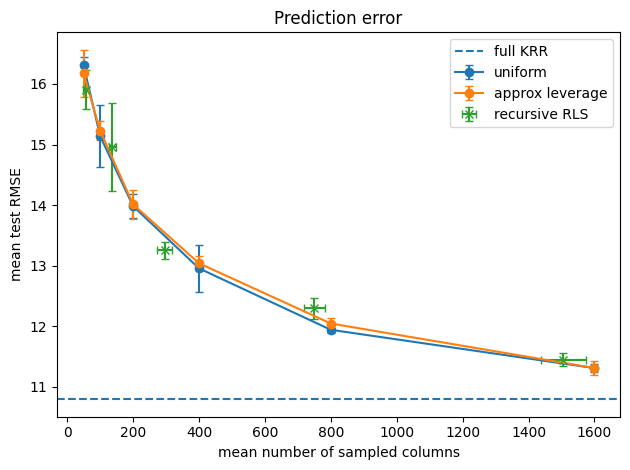

In [ ]:
# prediction error in original units

plt.figure()
for method in ["uniform", "approx leverage"]:
    sub = plot_df[plot_df["method"] == method].sort_values("l_mean")
    plt.errorbar(sub["l_mean"], sub["test_rmse_mean"], yerr=sub["test_rmse_std"], marker="o", capsize=3, label=method)
sub = plot_df[plot_df["method"] == "recursive RLS"]
plt.errorbar(sub["l_mean"], sub["test_rmse_mean"], xerr=sub["l_std"], yerr=sub["test_rmse_std"], fmt="x", capsize=3, linestyle="none", label="recursive RLS")
plt.axhline(np.sqrt(full_mse), linestyle="--", label="full KRR")
plt.xlabel("mean number of sampled columns")
plt.ylabel("mean test RMSE")
plt.title("Prediction error")
plt.legend()
plt.tight_layout()
#plt.savefig("../Results/" + dataset + "final_test_rmse_vs_l.pdf")
plt.show()

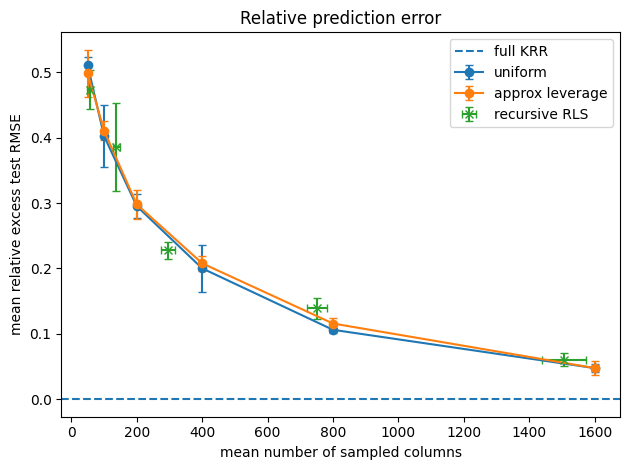

In [ ]:
# prediction error check

plt.figure()
for method in ["uniform", "approx leverage"]:
    sub = plot_df[plot_df["method"] == method].sort_values("l_mean")
    plt.errorbar(sub["l_mean"], sub["relative_excess_rmse_mean"], yerr=sub["relative_excess_rmse_std"], marker="o", capsize=3, label=method)
sub = plot_df[plot_df["method"] == "recursive RLS"]
plt.errorbar(sub["l_mean"], sub["relative_excess_rmse_mean"], xerr=sub["l_std"], yerr=sub["relative_excess_rmse_std"], fmt="x", capsize=3, linestyle="none", label="recursive RLS")
plt.axhline(0, linestyle="--", label="full KRR")
plt.xlabel("mean number of sampled columns")
plt.ylabel("mean relative excess test RMSE")
plt.title("Relative prediction error")
plt.legend()
plt.tight_layout()
#plt.savefig("../Results/" + dataset + "final_relative_excess_rmse_vs_l.pdf")
plt.show()

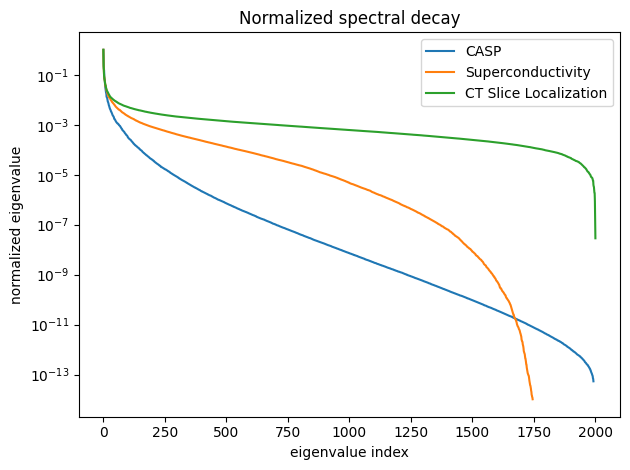

In [ ]:
# cross-dataset eigenvalue comparison

s_datasets = ["CASP", "Superconductivity", "CT Slice Localization"]
m_s = 2000

plt.figure()

for s_dataset in s_datasets:

    if s_dataset == "CASP":
        s_df = pd.read_csv("../Data/CASP.csv")
        s_X = s_df.iloc[:, 1:].to_numpy(dtype=float)

    elif s_dataset == "Superconductivity":
        s_df = pd.read_csv("../Data/train.csv")
        s_X = s_df.iloc[:, :-1].to_numpy(dtype=float)

    elif s_dataset == "CT Slice Localization":
        s_df = pd.read_csv("../Data/slice_localization_data.csv")
        s_X = s_df.iloc[:, 1:-1].to_numpy(dtype=float)

    s_rng = np.random.default_rng(split_seed)
    s_ind = s_rng.choice(s_X.shape[0], size=n_train + n_test, replace=False)
    s_X_train = s_X[s_ind[:n_train]]
    s_scaler = StandardScaler()
    s_X_train = s_scaler.fit_transform(s_X_train)
    s_K = rbf(s_X_train[:m_s], s_X_train[:m_s], gamma=1 / s_X_train.shape[1])
    s_eigenvalues = np.linalg.eigvalsh(s_K)[::-1]
    s_eigenvalues = np.maximum(s_eigenvalues, 0)
    s_eigenvalues = s_eigenvalues / s_eigenvalues[0]

    s_keep = s_eigenvalues > 1e-14
    plt.semilogy(np.arange(1, m_s + 1)[s_keep], s_eigenvalues[s_keep], label=s_dataset)

plt.xlabel("eigenvalue index")
plt.ylabel("normalized eigenvalue")
plt.title("Normalized spectral decay")
plt.legend()
plt.tight_layout()
#plt.savefig("../Results/cross_dataset_normalised_spectrum.pdf")
plt.show()